# Exploración inicial de la supervivencia en el Titanic

**MCDI503 · Exploración Inteligente para la Ciencia de Datos — Avance del Proyecto, Fase 1 (Evaluación Sumativa 1)**

## I. Identificación del proyecto

| Campo | Detalle |
|---|---|
| Título del avance | Exploración inicial de la supervivencia en el Titanic |
| Equipo | Grupo 10 |
| Integrantes | José Ignacio Rodríguez Cisternas · Sebastian Andrés Rojas Araya · Yerko Gallardo Miranda |
| Docente | Sergio Paraíso Medina |
| Fecha | 29 de noviembre de 2026 |
| Conjunto de datos | `titanic`, repositorio de datos de ejemplo de seaborn, cargado con `seaborn.load_dataset("titanic")` (891 pasajeros × 15 variables) |
| Propósito general | Implementar un primer ciclo de análisis exploratorio (EDA) reproducible y documentado que caracterice la calidad de los datos y describa cómo se distribuye la supervivencia observada según atributos de los pasajeros. |

**Cómo leer este notebook.** Las secciones siguen el flujo del EDA: contexto → carga → exploración → decisiones → resultados → supuestos → cierre. Cada bloque de código va precedido de una celda que indica *qué pregunta atiende, qué se hace y por qué*, y seguido de una interpretación del resultado. Las tablas y figuras están numeradas por sección (Tabla 3.1, Figura 3.1, …) para referenciarlas desde el informe PDF. Las decisiones exploratorias se identifican como **D1, D2, …** y se consolidan en la sección V.

**Cómo reproducirlo.** Desde la raíz del repositorio: `uv sync` y luego `uv run jupyter nbconvert --to notebook --execute --inplace sumativa1/notebooks/mcdi503_f1_sumativo_grupo10.ipynb` (o *Restart & Run All* en Jupyter/VS Code). Las versiones exactas de las librerías están fijadas en `uv.lock`.

## II. Contexto y objetivo exploratorio

### II.1 Contexto del problema

El 15 de abril de 1912 el RMS *Titanic* se hundió en su viaje inaugural entre Southampton y Nueva York. Murieron más de 1.500 de las aproximadamente 2.200 personas a bordo. Los botes salvavidas no alcanzaban para todos, y la evacuación se rigió en buena medida por el criterio de «mujeres y niños primero» y por el acceso a cubierta, que dependía de la clase del pasaje. Por eso la supervivencia no se distribuyó al azar entre los pasajeros.

El conjunto de datos `titanic` de seaborn registra **un pasajero por fila** (unidad de observación) con su resultado (`survived`), atributos sociodemográficos (`sex`, `age`, `who`), de viaje (`pclass`, `fare`, `embarked`, `deck`) y de grupo familiar (`sibsp`, `parch`, `alone`). Corresponde a 891 de los pasajeros y no incluye a la tripulación. Es el subconjunto de entrenamiento difundido por Kaggle a partir de registros históricos del pasaje.

**Problema que motiva la exploración.** Antes de cualquier modelamiento, hay que saber si los datos son confiables para estudiar la supervivencia y qué patrones descriptivos muestran. Hay faltantes, variables redundantes y registros sin identificador, que pueden sesgar cualquier conclusión si no se diagnostican primero.

**Valor del análisis.** El EDA documentado permite: (a) decidir con evidencia cómo tratar faltantes, duplicados y redundancias en las fases siguientes, (b) identificar los grupos (sexo, clase) con mayor y menor supervivencia observada como base para hipótesis posteriores, y (c) dejar una línea base reproducible que el equipo pueda ampliar sin rehacer el trabajo.

### II.2 Objetivo exploratorio del avance

> Caracterizar la estructura y la calidad del conjunto de datos `titanic` y describir cómo se distribuyen la edad, la tarifa y la supervivencia observada según sexo y clase. Cada decisión exploratoria debe quedar documentada y el flujo debe ser reproducible de principio a fin.

### II.3 Preguntas exploratorias iniciales

| Id | Pregunta | Evidencia esperada | Dónde se trabaja |
|---|---|---|---|
| **P1** | ¿Qué problemas de calidad presentan las variables clave y cómo condicionan el análisis? | Tabla de tipos, faltantes, valores fuera de dominio y repetidos, con decisiones justificadas | III.4 (diagnóstico) → V (decisiones) → VI (respuesta) |
| **P2** | ¿Cómo se distribuyen la edad y la tarifa? | Estadísticos descriptivos y gráficos, informando el número de observaciones válidas | IV → VI |
| **P3** | ¿Cómo varía la supervivencia observada según sexo y clase? | Pasajeros, sobrevivientes y tasa por grupo, incluido el cruce sexo × clase | IV → VI |

### II.4 Alcance y supuestos iniciales

- **Alcance:** primer ciclo de EDA, de carácter **descriptivo**. Abarca la carga, el diagnóstico de calidad, el análisis univariado de edad y tarifa, el bivariado de supervivencia según sexo y clase, y transformaciones básicas. No incluye modelos predictivos, pruebas de hipótesis ni imputación avanzada.
- **S1.** Cada fila corresponde a un pasajero distinto, aunque el dataset no trae un identificador (sin nombre, ticket ni `PassengerId`).
- **S2.** Los 891 registros son una **muestra** del pasaje, no el total a bordo. Las tasas describen esta muestra y no se generalizan sin cautela.
- **S3.** Las diferencias entre grupos se interpretan como **asociaciones descriptivas**, no como efectos causales.
- **S4.** Los valores registrados son correctos salvo evidencia de error (fuera de dominio o inconsistentes).

### II.5 Pertinencia del dataset elegido

Se eligió `titanic` sobre `mpg` y `penguins` (**D1**) porque es el único de los tres que permite cubrir todo el recorrido técnico pedido en la fase:
- tiene faltantes en distintas magnitudes;
- tiene variables numéricas y categóricas;
- tiene columnas redundantes y derivadas que hay que verificar;
- tiene registros repetidos sin identificador;
- tiene una variable de resultado binaria que permite el análisis bivariado y por subgrupos.

## III. Carga y revisión inicial de datos

### III.1 Configuración del entorno

**Qué y por qué.** Se importan las librerías y se registran las versiones de Python y de cada paquete, para que cualquier diferencia de resultados pueda atribuirse a una diferencia de entorno. Las rutas son relativas a la carpeta del notebook. Se fija una semilla para que eventuales muestreos posteriores sean repetibles.

In [1]:
import hashlib
import platform
import sys
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

SEED = 1042
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")

# Rutas relativas: BASE_DIR es la carpeta sumativa1/, tanto si el kernel arranca en
# sumativa1/notebooks/ (por defecto), en sumativa1/ o en la raíz del repositorio
_cwd = Path.cwd()
BASE_DIR = next((p for p in [_cwd, *_cwd.parents] if p.name == "sumativa1"), _cwd / "sumativa1")
RAW_DIR = BASE_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

entorno = pd.DataFrame(
    {
        "componente": ["Python", "Sistema", "pandas", "numpy", "matplotlib", "seaborn", "Ejecución"],
        "versión": [
            platform.python_version(),
            platform.platform(terse=True),
            pd.__version__,
            np.__version__,
            matplotlib.__version__,
            sns.__version__,
            datetime.now().strftime("%Y-%m-%d %H:%M"),
        ],
    }
)
entorno

,componente,versión
0,Python,3.14.10
1,Sistema,macOS-27.2.1
2,pandas,3.1.1
3,numpy,2.5.5
4,matplotlib,3.11.2
5,seaborn,0.13.2
6,Ejecución,2026-11-24 22:35


*Tabla 3.1 — Entorno de ejecución.* Las versiones mostradas coinciden con las fijadas en `uv.lock`. Si otra persona ejecuta el notebook con versiones distintas, esta tabla lo deja en evidencia.

### III.2 Carga del conjunto de datos

La fuente original es `titanic` de seaborn. **D2 (actualizada en el traspaso):** se lee la copia congelada incluida en el repositorio y se comprueba su SHA-256 **antes** de interpretarla. Así se reproduce el análisis sin conexión y no se sobrescribe la evidencia original. Se restauran los tipos categóricos que aplica `sns.load_dataset`. **D3:** `df_raw` conserva los datos de entrada y `df` es la copia de trabajo.

In [2]:
DATASET = "titanic"
SHA256_ESPERADO = "81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2"
FORMA_ESPERADA = (891, 15)
copia_raw = RAW_DIR / "titanic_seaborn.csv"
if not copia_raw.is_file():
    raise FileNotFoundError(f"Falta la copia congelada del repositorio: {copia_raw}")
sha256 = hashlib.sha256(copia_raw.read_bytes()).hexdigest()
assert sha256 == SHA256_ESPERADO, "La copia no coincide con la fuente registrada; revisar antes de continuar."
df_raw = pd.read_csv(copia_raw)
df_raw["class"] = pd.Categorical(df_raw["class"], categories=["First", "Second", "Third"], ordered=True)
df_raw["deck"] = pd.Categorical(df_raw["deck"], categories=list("ABCDEFG"), ordered=True)
assert df_raw.shape == FORMA_ESPERADA
print("Fuente original: https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv")
print(f"Copia verificada: {copia_raw.relative_to(BASE_DIR)}")
print(f"SHA-256: {sha256} | Dimensiones: {df_raw.shape}")
df = df_raw.copy(deep=True)
original_control = df_raw.copy(deep=True)


Fuente original: https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv
Copia verificada: data/raw/titanic_seaborn.csv
SHA-256: 81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2 | Dimensiones: (891, 15)


**Resultado.** La huella coincide con la registrada y las dimensiones son 891 × 15. Los datos de entrada son exactamente los mismos en cada ejecución, y cualquier cambio en la fuente detiene el notebook con un mensaje explícito.

### III.3 Estructura del conjunto de datos

**Qué y por qué.** Se revisan las primeras filas, los tipos de datos y el significado de cada variable. Así se confirma la unidad de observación (un pasajero por fila) y se asigna un rol a cada columna antes de explorarla.

In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.00,1,0,7.25,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.00,1,0,71.28,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.00,0,0,7.92,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.00,1,0,53.10,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.00,0,0,8.05,S,Third,man,True,NaN,Southampton,no,True


*Tabla 3.2 — Primeras cinco filas del dataset.*

In [4]:
descripcion = {
    "survived": ("Sobrevivió (0 = no, 1 = sí)", "Objetivo"),
    "pclass": ("Clase del pasaje (1, 2, 3)", "Explicativa"),
    "sex": ("Sexo del pasajero", "Explicativa"),
    "age": ("Edad en años", "Explicativa"),
    "sibsp": ("N.º de hermanos/cónyuges a bordo", "Explicativa"),
    "parch": ("N.º de padres/hijos a bordo", "Explicativa"),
    "fare": ("Tarifa pagada (libras esterlinas)", "Explicativa"),
    "embarked": ("Puerto de embarque (C, Q, S)", "Explicativa"),
    "class": ("Clase del pasaje en texto", "Redundante con pclass"),
    "who": ("Categoría: man / woman / child", "Derivada de sex y age"),
    "adult_male": ("Hombre adulto (bool)", "Derivada de who"),
    "deck": ("Cubierta del camarote (A–G)", "Explicativa"),
    "embark_town": ("Ciudad de embarque", "Redundante con embarked"),
    "alive": ("Sobrevivió (no / yes)", "Redundante con survived"),
    "alone": ("Viaja solo (sibsp + parch = 0)", "Derivada de sibsp y parch"),
}

diccionario = pd.DataFrame(
    {
        "tipo": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "valores_distintos": df.nunique(),
        "descripción": [descripcion[c][0] for c in df.columns],
        "rol": [descripcion[c][1] for c in df.columns],
    }
)
diccionario.index.name = "variable"
diccionario

,tipo,no_nulos,valores_distintos,descripción,rol
variable,,,,,
survived,int64,891,2,"Sobrevivió (0 = no, 1 = sí)",Objetivo
pclass,int64,891,3,"Clase del pasaje (1, 2, 3)",Explicativa
sex,str,891,2,Sexo del pasajero,Explicativa
age,float64,714,88,Edad en años,Explicativa
sibsp,int64,891,7,N.º de hermanos/cónyuges a bordo,Explicativa
parch,int64,891,7,N.º de padres/hijos a bordo,Explicativa
fare,float64,891,248,Tarifa pagada (libras esterlinas),Explicativa
embarked,str,889,3,"Puerto de embarque (C, Q, S)",Explicativa
class,category,891,3,Clase del pasaje en texto,Redundante con pclass


*Tabla 3.3 — Diccionario de variables: tipo, valores no nulos, cardinalidad y rol en el análisis.*

**Observaciones iniciales.**
- Hay 6 variables numéricas (`survived`, `pclass`, `age`, `sibsp`, `parch`, `fare`), 7 categóricas o de texto y 2 booleanas.
- `survived` y `pclass` son numéricas, pero conceptualmente son categóricas: binaria y ordinal. Se tratarán como tales al agrupar.
- De las 15 columnas, **3 son redundantes** (`class`, `alive`, `embark_town`) y **3 son derivadas** de otras (`who`, `adult_male`, `alone`). El conjunto de información independiente es menor de lo que sugiere el número de columnas (ver III.4.3).
- `age`, `embarked`, `deck` y `embark_town` tienen menos de 891 valores no nulos, es decir, presentan faltantes (ver III.4.1).

### III.4 Diagnóstico de calidad de los datos (P1)

Esta subsección aporta la evidencia para **P1**. Revisa cuatro dimensiones de calidad: completitud (faltantes), validez (dominios y rangos), consistencia (variables redundantes o derivadas) y unicidad (registros repetidos). Al final, la Tabla 3.9 resume el diagnóstico. **En esta sección no se modifica ningún dato.** Las decisiones de tratamiento se registran aquí y se implementan en la sección V.

#### III.4.1 Valores faltantes

In [5]:
faltantes = (
    pd.DataFrame({"faltantes": df.isna().sum(), "porcentaje": df.isna().mean() * 100})
    .query("faltantes > 0")
    .sort_values("faltantes", ascending=False)
)
faltantes["válidos"] = len(df) - faltantes["faltantes"]
faltantes

,faltantes,porcentaje,válidos
deck,688,77.22,203
age,177,19.87,714
embarked,2,0.22,889
embark_town,2,0.22,889


*Tabla 3.4 — Variables con valores faltantes (conteo, porcentaje sobre 891 y observaciones válidas).*

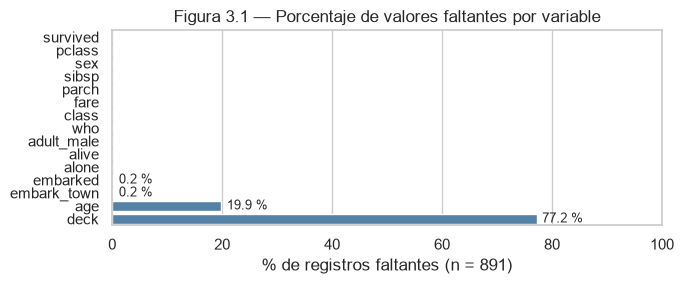

In [6]:
fig, ax = plt.subplots(figsize=(7, 3))
pct = (df.isna().mean() * 100).sort_values()
sns.barplot(x=pct.values, y=pct.index, ax=ax, color="steelblue")
for i, v in enumerate(pct.values):
    if v > 0:
        ax.text(v + 1, i, f"{v:.1f} %", va="center", fontsize=9)
ax.set(xlabel="% de registros faltantes (n = 891)", ylabel="", xlim=(0, 100),
       title="Figura 3.1 — Porcentaje de valores faltantes por variable")
plt.tight_layout()
plt.show()

**Interpretación.**
- **`deck` (77,2 % faltante).** Solo 203 pasajeros tienen cubierta registrada. Con tan poca información, cualquier conclusión sobre la cubierta es frágil, y la imputación no es razonable. Lo más probable es que el faltante no sea aleatorio: el registro de camarotes se conservó sobre todo para la primera clase. Esto se verificará en la sección IV.
- **`age` (19,9 % faltante, 714 válidos).** Afecta directamente a **P2** y a `who`. Todo cálculo sobre la edad debe informar que usa 714 observaciones. **D6:** en esta fase no se imputa; los 177 registros sin edad se conservan para los análisis que no dependen de ella.
- **`embarked` / `embark_town` (2 registros, 0,2 %).** El impacto es despreciable. Los dos faltantes son los mismos registros en ambas columnas (se verifica en III.4.3).
- Las variables de **P3** (`survived`, `sex`, `pclass`) están **completas**, así que P3 puede responderse con los 891 pasajeros.

#### III.4.2 Dominios y rangos

**Qué y por qué.** Se comprueba que cada variable tome solo valores admisibles: categorías esperadas, rangos plausibles y ningún negativo. Si hubiera valores fuera de dominio serían errores, y habría que corregirlos antes de describir distribuciones.

In [7]:
dominios = {
    "survived": {0, 1},
    "pclass": {1, 2, 3},
    "sex": {"male", "female"},
    "embarked": {"C", "Q", "S"},
    "deck": set("ABCDEFG"),
    "who": {"man", "woman", "child"},
}
filas = []
for col, permitidos in dominios.items():
    obs = df[col].dropna()
    filas.append({
        "variable": col,
        "dominio esperado": ", ".join(map(str, sorted(permitidos))),
        "valores observados": ", ".join(map(str, sorted(obs.unique()))),
        "fuera de dominio": int((~obs.isin(permitidos)).sum()),
    })

rangos = {"age": (0, 100), "fare": (0, 600), "sibsp": (0, 10), "parch": (0, 10)}
for col, (lo, hi) in rangos.items():
    obs = df[col].dropna()
    filas.append({
        "variable": col,
        "dominio esperado": f"[{lo}, {hi}]",
        "valores observados": f"mín {obs.min():g} · máx {obs.max():g}",
        "fuera de dominio": int((~obs.between(lo, hi)).sum()),
    })

tabla_dominios = pd.DataFrame(filas).set_index("variable")
tabla_dominios

,dominio esperado,valores observados,fuera de dominio
variable,,,
survived,"0, 1","0, 1",0
pclass,"1, 2, 3","1, 2, 3",0
sex,"female, male","female, male",0
embarked,"C, Q, S","C, Q, S",0
deck,"A, B, C, D, E, F, G","A, B, C, D, E, F, G",0
who,"child, man, woman","child, man, woman",0
age,"[0, 100]",mín 0.42 · máx 80,0
fare,"[0, 600]",mín 0 · máx 512.329,0
sibsp,"[0, 10]",mín 0 · máx 8,0


*Tabla 3.5 — Verificación de dominios categóricos y rangos numéricos.*

In [8]:
edad = df["age"].dropna()
casos_especiales = pd.Series({
    "Tarifa igual a 0": int((df["fare"] == 0).sum()),
    "Edad < 1 año (fraccionaria, en meses)": int((edad < 1).sum()),
    "Edad ≥ 1 terminada en ,5 (edad estimada)": int(((edad >= 1) & (edad % 1 == 0.5)).sum()),
    "Tarifa > 500": int((df["fare"] > 500).sum()),
}, name="registros")
casos_especiales.to_frame()

,registros
Tarifa igual a 0,15
"Edad < 1 año (fraccionaria, en meses)",7
"Edad ≥ 1 terminada en ,5 (edad estimada)",18
Tarifa > 500,3


*Tabla 3.6 — Casos especiales dentro del dominio, que no son errores pero conviene registrar.*

**Interpretación.**
- **Ninguna variable presenta valores fuera de dominio.** Las categorías y los rangos son válidos.
- Hay tres casos que no son errores, pero sí afectan la lectura de **P2**:
  - **15 tarifas iguales a 0.** Son plausibles (pasajes de cortesía o de personal de la naviera), pero bajan la media de `fare`. Se mantienen y se señalarán al describir la tarifa.
  - **Edades fraccionarias.** Según la documentación original del dataset, las edades menores de 1 año se expresan en fracción y las edades terminadas en ,5 son **estimadas** (18 casos). Se aceptan como válidas, con la salvedad de que la edad tiene cierta imprecisión.
  - **Tarifas mayores a 500** (3 registros con 512,33). Son valores extremos reales de primera clase, no errores. Anticipan una distribución de `fare` muy asimétrica (ver IV).

#### III.4.3 Consistencia de variables redundantes y derivadas

**Qué y por qué.** Si dos columnas representan la misma información, deben coincidir siempre. Si no coinciden, hay un error de registro. Además, conviene saber cómo se construyeron las columnas derivadas para no tomarlas como evidencia independiente.

In [9]:
es_adulto_hombre = df["who"].eq("man")
verificaciones = pd.Series({
    "pclass ↔ class (1/2/3 = First/Second/Third)":
        (df["pclass"].map({1: "First", 2: "Second", 3: "Third"}) == df["class"].astype(str)).all(),
    "survived ↔ alive (1/0 = yes/no)":
        (df["survived"].map({1: "yes", 0: "no"}) == df["alive"]).all(),
    "embarked ↔ embark_town (C/Q/S)":
        (df["embarked"].map({"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"})
         .fillna("NA") == df["embark_town"].fillna("NA")).all(),
    "adult_male ↔ who == 'man'":
        (df["adult_male"] == es_adulto_hombre).all(),
    "alone ↔ sibsp + parch == 0":
        (df["alone"] == (df["sibsp"] + df["parch"]).eq(0)).all(),
}, name="consistente")
verificaciones.to_frame()

,consistente
pclass ↔ class (1/2/3 = First/Second/Third),True
survived ↔ alive (1/0 = yes/no),True
embarked ↔ embark_town (C/Q/S),True
adult_male ↔ who == 'man',True
alone ↔ sibsp + parch == 0,True


*Tabla 3.7a — Coincidencia entre pares de variables redundantes o derivadas.*

In [10]:
who_por_edad = pd.crosstab(
    df["age"].isna().map({True: "edad faltante", False: "edad registrada"}),
    df["who"],
    margins=True, margins_name="Total",
)
who_por_edad

who,child,man,woman,Total
age,,,,
edad faltante,0,124,53,177
edad registrada,83,413,218,714
Total,83,537,271,891


*Tabla 3.7b — Categoría `who` según si la edad está registrada.*

**Interpretación.**
- Los cinco pares redundantes o derivados son **100 % consistentes**. No hay contradicciones, y los 2 faltantes de `embarked` coinciden con los de `embark_town`.
- `class`, `alive` y `embark_town` repiten exactamente la información de `pclass`, `survived` y `embarked`. **D5:** se marcan como redundantes, pero **no se eliminan todavía**. `df_raw` debe seguir íntegro, y la sección V decidirá cuáles retirar de la copia de trabajo.
- **Hallazgo relevante para P3 y para cualquier análisis con `who`.** Los 177 pasajeros sin edad aparecen clasificados como `man` (124) o `woman` (53), nunca como `child`. Es decir, `who` **asume que los pasajeros sin edad son adultos**. Algunos niños pueden estar mal clasificados, así que `who` y `adult_male` no deben usarse como sustituto de la edad. Se registra como limitación.

#### III.4.4 Registros repetidos

**Qué y por qué.** Una fila repetida podría ser un error de carga, y en ese caso inflaría los conteos de P3. Pero este dataset **no tiene identificador único** (no incluye nombre, ticket ni `PassengerId`). Antes de eliminar registros, hay que revisar si las coincidencias pueden corresponder a personas distintas con atributos iguales.

In [11]:
duplicados = df[df.duplicated(keep=False)]
resumen_dup = pd.Series({
    "Filas idénticas a otra anterior (duplicated)": int(df.duplicated().sum()),
    "Filas que participan en algún grupo repetido": len(duplicados),
    "% de esas filas con algún faltante (age o deck)": round(duplicados.isna().any(axis=1).mean() * 100, 1),
    "% de esas filas en 3.ª clase": round(duplicados["pclass"].eq(3).mean() * 100, 1),
}, name="valor", dtype=object)
display(resumen_dup.to_frame())

grupos_dup = (
    duplicados.groupby(list(df.columns), dropna=False, observed=True)
    .size().rename("repeticiones").sort_values(ascending=False).reset_index()
)
grupos_dup[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked", "deck", "repeticiones"]].head(8)

,valor
Filas idénticas a otra anterior (duplicated),107
Filas que participan en algún grupo repetido,160
% de esas filas con algún faltante (age o deck),98.80
% de esas filas en 3.ª clase,78.10


,survived,pclass,sex,age,sibsp,parch,fare,embarked,deck,repeticiones
0,0,3,male,NaN,0,0,7.90,S,NaN,13
1,0,3,male,NaN,0,0,8.05,S,NaN,12
2,0,3,male,NaN,0,0,7.75,Q,NaN,8
3,1,3,female,NaN,0,0,7.75,Q,NaN,7
4,0,2,male,NaN,0,0,0.00,S,NaN,6
5,0,3,male,NaN,0,0,7.23,C,NaN,5
6,0,3,male,NaN,0,0,7.22,C,NaN,5
7,0,3,male,NaN,8,2,69.55,S,NaN,4


*Tabla 3.8a — Magnitud de los registros repetidos. Tabla 3.8b — Combinaciones más repetidas.*

**Interpretación y decisión.**
- Hay **107 filas idénticas a otra anterior**, que forman grupos con un total de 160 filas.
- Casi todas (~99 %) tienen la edad o la cubierta sin registrar y corresponden sobre todo a hombres de 3.ª clase que viajaban solos.
- Las tarifas son estándar y se repiten mucho en ese segmento: 7,90, 8,05 y 7,75 libras.

Sin nombre ni ticket, las coincidencias **podrían corresponder a personas distintas** cuyos atributos registrados son iguales; no es posible confirmar ni descartar una duplicación de carga. Por eso, **D4:** **no se eliminan** los registros repetidos, de acuerdo con el supuesto S1. Eliminarlos quitaría 107 registros (12 % de la muestra) y podría sesgar P3 si corresponden a personas distintas. Se registra como limitación: con este dataset no es posible verificar la unicidad de los pasajeros.

#### III.4.5 Resumen del diagnóstico de calidad (P1)

In [12]:
resumen_calidad = pd.DataFrame(
    [
        ["Completitud", "deck", "688 faltantes (77,2 %)", "Alto: no apta para conclusiones", "Analizar solo como presencia/ausencia; sin imputar (V)"],
        ["Completitud", "age", "177 faltantes (19,9 %)", "Medio: P2 usa n = 714", "D6: sin imputar en esta fase; informar n válidos"],
        ["Completitud", "embarked / embark_town", "2 faltantes (0,2 %)", "Bajo", "Excluir solo en análisis por puerto"],
        ["Validez", "todas", "0 valores fuera de dominio", "Ninguno", "Sin acción"],
        ["Validez", "fare", "15 tarifas = 0; 3 > 500", "Medio en P2 (asimetría)", "Mantener; usar mediana y escala adecuada (IV)"],
        ["Validez", "age", "18 edades estimadas (,5)", "Bajo", "Mantener; registrar imprecisión"],
        ["Consistencia", "class, alive, embark_town", "100 % redundantes", "Ninguno (sin contradicciones)", "D5: marcar; decidir retiro en V"],
        ["Consistencia", "who / adult_male", "Edad faltante → siempre adulto", "Medio: posible mala clasificación", "No usar como sustituto de age"],
        ["Unicidad", "fila completa", "107 filas repetidas", "Medio: sin ID no verificable", "D4: conservar (personas distintas)"],
    ],
    columns=["dimensión", "variable", "hallazgo", "impacto en el análisis", "decisión / acción"],
)
resumen_calidad.index = resumen_calidad.index + 1
resumen_calidad

,dimensión,variable,hallazgo,impacto en el análisis,decisión / acción
1,Completitud,deck,"688 faltantes (77,2 %)",Alto: no apta para conclusiones,Analizar solo como presencia/ausencia; sin imp...
2,Completitud,age,"177 faltantes (19,9 %)",Medio: P2 usa n = 714,D6: sin imputar en esta fase; informar n válidos
3,Completitud,embarked / embark_town,"2 faltantes (0,2 %)",Bajo,Excluir solo en análisis por puerto
4,Validez,todas,0 valores fuera de dominio,Ninguno,Sin acción
5,Validez,fare,15 tarifas = 0; 3 > 500,Medio en P2 (asimetría),Mantener; usar mediana y escala adecuada (IV)
6,Validez,age,"18 edades estimadas (,5)",Bajo,Mantener; registrar imprecisión
7,Consistencia,"class, alive, embark_town",100 % redundantes,Ninguno (sin contradicciones),D5: marcar; decidir retiro en V
8,Consistencia,who / adult_male,Edad faltante → siempre adulto,Medio: posible mala clasificación,No usar como sustituto de age
9,Unicidad,fila completa,107 filas repetidas,Medio: sin ID no verificable,D4: conservar (personas distintas)


*Tabla 3.9 — Resumen del diagnóstico de calidad: evidencia para P1.*

### III.5 Síntesis de la sección III

- El dataset se cargó de forma reproducible: la fuente está verificada con SHA-256, hay una copia congelada y `df_raw` se mantiene intacto. Tiene **891 pasajeros y 15 variables**, de las cuales solo **9 aportan información independiente**.
- **Respuesta preliminar a P1.** La calidad es buena en validez y consistencia: no hay valores fuera de dominio ni contradicciones. Los problemas están en la **completitud** (`deck` casi inutilizable; `age` con 20 % faltante, lo que condiciona P2) y en la **unicidad**, que no se puede verificar por falta de identificador. Las variables de P3 están completas.
- Las decisiones D1–D6 están identificadas y se consolidan en la sección V. La sección IV continúa con la exploración de P2 y P3 sobre `df`.

## IV. Exploración preliminar

### IV.1 Distribuciones de edad y tarifa (P2)

Se valida el traspaso con la huella, dimensiones y conteos de faltantes. Se resume cada variable con sus observaciones disponibles, sin eliminar del conjunto completo a quienes no tienen edad. Se informa media, mediana, desviación estándar muestral y cuartiles. La tarifa se expresa en libras esterlinas registradas, sin ajuste monetario.

In [13]:
assert df.shape == (891, 15)
assert df.isna().sum().loc[["deck", "age", "embarked", "embark_town"]].tolist() == [688, 177, 2, 2]
assert df.duplicated().sum() == 107
assert tabla_dominios["fuera de dominio"].sum() == 0
assert verificaciones.all()
resumen_p2 = df[["age", "fare"]].describe().T.rename(columns={
    "count": "n válidos", "mean": "media", "std": "DE muestral",
    "min": "mínimo", "25%": "Q1", "50%": "mediana", "75%": "Q3", "max": "máximo"})
resumen_p2.insert(0, "unidad", ["años", "libras esterlinas"])
resumen_p2.insert(2, "faltantes", df[["age", "fare"]].isna().sum())
print("Tabla 4.1 — Estadísticos descriptivos por variable")
display(resumen_p2)


Tabla 4.1 — Estadísticos descriptivos por variable


,unidad,n válidos,faltantes,media,DE muestral,mínimo,Q1,mediana,Q3,máximo
age,años,714.00,177,29.70,14.53,0.42,20.12,28.00,38.00,80.00
fare,libras esterlinas,891.00,0,32.20,49.69,0.00,7.91,14.45,31.00,512.33


**Interpretación (Tabla 4.1).** La edad tiene 714 valores válidos y 177 faltantes: mediana 28 años, media 29,70 y la mitad central entre 20,125 y 38 años. Esto describe a los pasajeros con edad registrada. La tarifa usa 891 registros: mediana 14,45 libras frente a media 32,20 y máximo 512,33; la separación entre media y mediana indica asimetría hacia valores altos. La mediana y los cuartiles complementan la media para evitar que los extremos dominen la descripción.

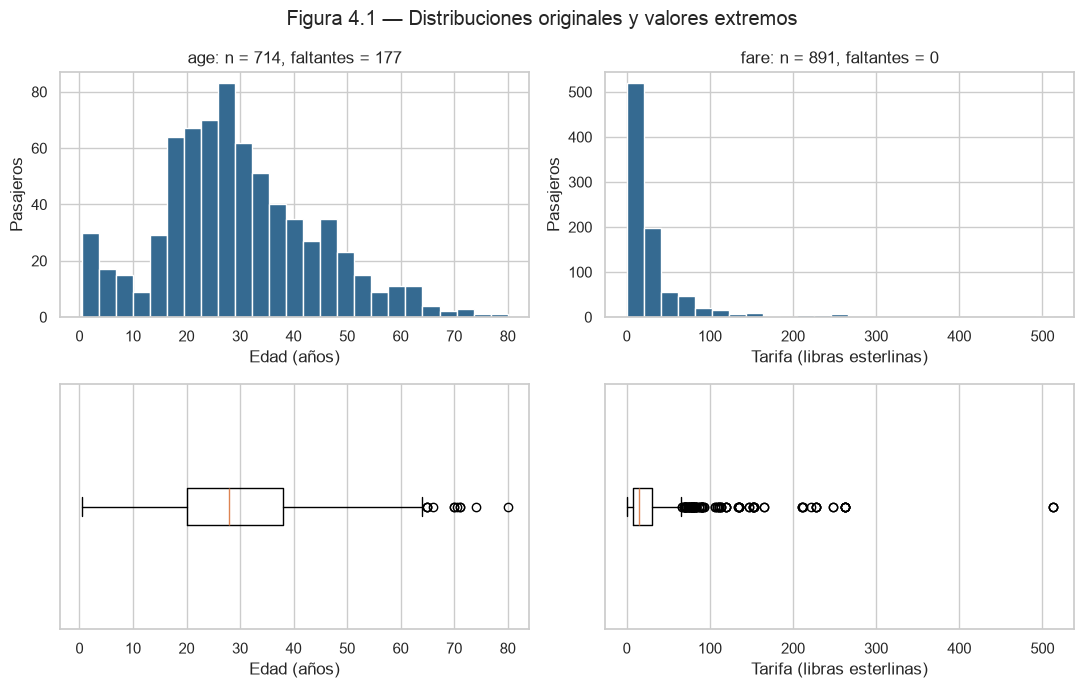

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, (col, etiqueta) in enumerate([("age", "Edad (años)"), ("fare", "Tarifa (libras esterlinas)")]):
    valores = df[col].dropna()
    axes[0, j].hist(valores, bins=25, color="#356a91", edgecolor="white")
    axes[0, j].set(title=f"{col}: n = {len(valores)}, faltantes = {df[col].isna().sum()}", xlabel=etiqueta, ylabel="Pasajeros")
    axes[1, j].boxplot(valores, orientation="horizontal")
    axes[1, j].set(xlabel=etiqueta, yticks=[])
fig.suptitle("Figura 4.1 — Distribuciones originales y valores extremos")
fig.tight_layout()
plt.show()


**Interpretación (Figura 4.1).** Las edades se concentran en adultos jóvenes; los extremos del diagrama de caja son observaciones alejadas según el criterio de 1,5 rangos intercuartílicos, no errores demostrados. La tarifa presenta una cola derecha larga. Se conservan las 15 tarifas de cero y los tres valores superiores a 500: el archivo por sí solo no permite establecer el motivo de cada tarifa. La sección V añade una representación logarítmica sin modificar la tarifa original.

### IV.2 Disponibilidad de edad y cubierta según clase

Se comprueba la sospecha planteada en III.4.1: ¿la disponibilidad de `deck` cambia por clase? Se incluye la edad para valorar la limitación de P2. Los porcentajes se calculan dentro de cada clase, no sobre el total general.

In [15]:
calidad_clase = df.groupby("pclass", observed=True).agg(
    pasajeros=("survived", "size"), edad_disponible=("age", "count"), cubierta_disponible=("deck", "count"))
for prefijo, disponible in [("edad", "edad_disponible"), ("cubierta", "cubierta_disponible")]:
    calidad_clase[f"{prefijo}_faltantes"] = calidad_clase["pasajeros"] - calidad_clase[disponible]
    calidad_clase[f"{prefijo}_faltante_pct"] = 100 * calidad_clase[f"{prefijo}_faltantes"] / calidad_clase["pasajeros"]
print("Tabla 4.2 — Disponibilidad por clase; porcentajes dentro de cada grupo")
display(calidad_clase)


Tabla 4.2 — Disponibilidad por clase; porcentajes dentro de cada grupo


,pasajeros,edad_disponible,cubierta_disponible,edad_faltantes,edad_faltante_pct,cubierta_faltantes,cubierta_faltante_pct
pclass,,,,,,,
1,216,186,175,30,13.89,41,18.98
2,184,173,16,11,5.98,168,91.30
3,491,355,12,136,27.70,479,97.56


**Interpretación (Tabla 4.2).** Falta cubierta en 18,98 % de primera clase, 91,30 % de segunda y 97,56 % de tercera. Su disponibilidad está asociada con la clase; no se demuestra el mecanismo que produjo los faltantes. También falta edad en 13,89 %, 5,98 % y 27,70 %, respectivamente. Por ello, la distribución de edad observada no tiene necesariamente la misma composición que la muestra completa. No se imputan edades ni se extrapolan los resultados de cubierta a todos los pasajeros.

### IV.3 Composición de las variables de P3

Se muestran las frecuencias antes de comparar tasas, para reconocer grupos de distinto tamaño y verificar que las tres variables están completas.

In [16]:
composicion = pd.concat([
    df[col].value_counts(dropna=False).rename_axis("valor").reset_index(name="pasajeros").assign(variable=col)
    for col in ["survived", "sex", "pclass"]
], ignore_index=True)
composicion["porcentaje"] = 100 * composicion["pasajeros"] / len(df)
print("Tabla 4.3 — Composición de la muestra (n = 891)")
display(composicion[["variable", "valor", "pasajeros", "porcentaje"]])


Tabla 4.3 — Composición de la muestra (n = 891)


,variable,valor,pasajeros,porcentaje
0,survived,0,549,61.62
1,survived,1,342,38.38
2,sex,male,577,64.76
3,sex,female,314,35.24
4,pclass,3,491,55.11
5,pclass,1,216,24.24
6,pclass,2,184,20.65


**Interpretación (Tabla 4.3).** Hay 342 sobrevivientes (38,38 %) y 549 fallecidos. La muestra contiene 314 mujeres y 577 hombres; las clases 1, 2 y 3 tienen 216, 184 y 491 pasajeros. Los conteos de sobrevivientes deben compararse mediante tasas con su denominador, pues los tamaños de los grupos son diferentes.

## V. Decisiones y transformaciones iniciales

### V.1 Registro de decisiones exploratorias

| Id | Decisión | Motivo | Resultado intermedio | Sección |
|---|---|---|---|---|
| D1 | Usar el dataset `titanic` | Es el único que cubre faltantes, redundancias, repetidos y un resultado binario para el análisis bivariado | Dataset de 891 × 15 con todos los componentes de la fase | II.5 |
| D2 | Leer la copia congelada de seaborn y verificar SHA-256 antes de cargarla | La fuente remota puede cambiar; la carga debe ser idéntica en cada ejecución | Huella `81787d32…` verificada; `data/raw/titanic_seaborn.csv` | III.2 |
| D3 | Conservar `df_raw` intacto y trabajar sobre `df` | Mantener trazable la relación entre los datos de entrada y los transformados | `df_raw` sin cambios en todo el notebook | III.2 |
| D4 | No eliminar las 107 filas repetidas | Sin identificador, podrían ser pasajeros distintos; eliminarlas podría sesgar P3 | Se mantienen las 891 filas | III.4.4 |
| D5 | Marcar `class`, `alive` y `embark_town` como redundantes sin borrarlas aún | Son 100 % consistentes con `pclass`, `survived` y `embarked`; el retiro se decide en V | 15 columnas, 9 con información independiente | III.4.3 |
| D6 | No imputar `age` en esta fase | El 19,9 % faltante condiciona P2; imputar sin explorar antes introduciría supuestos no verificados | P2 se calcula con n = 714 y se conservan las 177 filas | III.4.1 |
| D7 | Retirar `class`, `alive` y `embark_town` de `df` | Redundancia verificada en Tabla 3.7a | 891 × 15 → 891 × 12; `df_raw` intacto | V.2 |
| D8 | Crear máscaras de análisis por pregunta, sin borrado global ni imputación | Edad incompleta; P3 usa variables completas | P2 edad: 714 incluidos y 177 excluidos; tarifa y P3: 891 | V.2 |
| D9 | Conservar ceros y extremos de tarifa; complementar con `log1p(fare)` | Asimetría; no hay evidencia suficiente para corregir esos registros | 15 ceros y 3 tarifas > 500 conservados; una columna adicional, 13 en total | V.2 |
| D10 | Diagnosticar faltantes por clase, sin usar `deck` ni `who` como sustitutos de edad | La disponibilidad de información difiere entre clases | Tabla 4.2: falta edad en 27,70 % de tercera clase | IV.2 |
| D11 | Mostrar denominadores y sobrevivientes por sexo, clase y cruce | Tasas agregadas pueden ocultar composición de grupos | Tres agrupaciones de 891 pasajeros y 342 sobrevivientes cada una | VI.3 |

No se eliminan filas ni se imputan valores. Las cifras siguientes verifican el efecto de las decisiones; las categorías se usan para agrupar, no como magnitudes continuas.

### V.2 Implementación y comprobación de las decisiones

In [17]:
# Reconstruir desde el original hace esta celda repetible sin acumular transformaciones.
df = df_raw.copy(deep=True)
columnas_redundantes = ["class", "alive", "embark_town"]
columnas_antes = df.shape[1]
df = df.drop(columns=columnas_redundantes)
columnas_sin_redundancia = df.shape[1]
df["fare_log1p"] = np.log1p(df["fare"])
mask_edad = df["age"].notna()
mask_tarifa = df["fare"].notna()
mask_p3 = df[["survived", "sex", "pclass"]].notna().all(axis=1)
trazabilidad = pd.DataFrame([
    ["D7: columnas redundantes", columnas_antes, columnas_sin_redundancia, "columnas; 891 filas conservadas"],
    ["D8: edad", len(df), int(mask_edad.sum()), "177 excluidos solo del cálculo de edad"],
    ["D8: tarifa", len(df), int(mask_tarifa.sum()), "sin exclusiones"],
    ["D8: supervivencia", len(df), int(mask_p3.sum()), "sin exclusiones"],
    ["D9: añadir fare_log1p", columnas_sin_redundancia, df.shape[1], "columnas; tarifa original intacta"],
    ["D9: tarifas cero", int(df_raw.fare.eq(0).sum()), int(df.fare.eq(0).sum()), "registros conservados"],
    ["D9: tarifas > 500", int(df_raw.fare.gt(500).sum()), int(df.fare.gt(500).sum()), "registros conservados"],
], columns=["decisión", "antes", "después", "alcance"])
print("Tabla 5.1 — Evidencias antes y después")
display(trazabilidad)
pd.testing.assert_frame_equal(df_raw, original_control)
pd.testing.assert_frame_equal(df[df_raw.columns.difference(columnas_redundantes)],
                              df_raw[df_raw.columns.difference(columnas_redundantes)])
assert df.index.equals(df_raw.index) and len(df) == 891
assert (int(mask_edad.sum()), int(mask_tarifa.sum()), int(mask_p3.sum())) == (714, 891, 891)
assert np.isfinite(df["fare_log1p"]).all()
assert np.allclose(np.expm1(df["fare_log1p"]), df["fare"])


Tabla 5.1 — Evidencias antes y después


,decisión,antes,después,alcance
0,D7: columnas redundantes,15,12,columnas; 891 filas conservadas
1,D8: edad,891,714,177 excluidos solo del cálculo de edad
2,D8: tarifa,891,891,sin exclusiones
3,D8: supervivencia,891,891,sin exclusiones
4,D9: añadir fare_log1p,12,13,columnas; tarifa original intacta
5,D9: tarifas cero,15,15,registros conservados
6,D9: tarifas > 500,3,3,registros conservados


**Interpretación (Tabla 5.1).** Se pasa de 15 a 12 columnas al retirar las tres redundantes y a 13 al añadir `fare_log1p`. Las 891 filas se conservan. La edad excluye 177 observaciones únicamente de sus resúmenes; P3 utiliza las 891. Las comprobaciones aseguran que `df_raw` y los valores originales retenidos no cambiaron. `log1p` transforma cada tarifa en ln(1 + tarifa), conserva los ceros y sirve solo para visualizar; las cifras monetarias se reportan en la escala original.

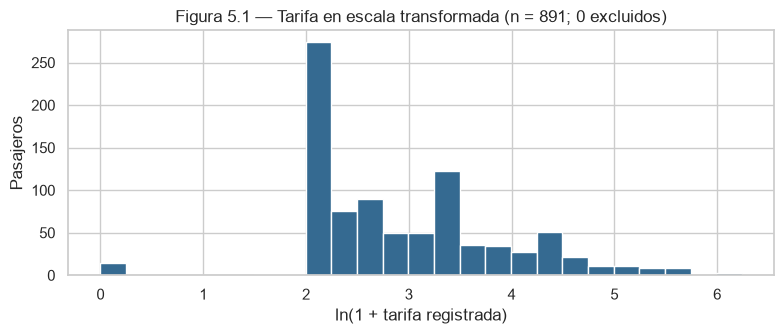

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df.loc[mask_tarifa, "fare_log1p"], bins=25, color="#356a91", edgecolor="white")
ax.set(xlabel="ln(1 + tarifa registrada)", ylabel="Pasajeros",
       title="Figura 5.1 — Tarifa en escala transformada (n = 891; 0 excluidos)")
fig.tight_layout()
plt.show()


**Interpretación (Figura 5.1).** La transformación comprime los valores altos y permite distinguir mejor el cuerpo de la distribución. La acumulación en cero sigue visible. Esta representación no demuestra normalidad, no corrige datos y no justifica eliminar los extremos.

## VI. Resultados e interpretación inicial

### VI.1 Respuesta a P1

La calidad permite describir supervivencia por sexo y clase con los 891 registros, pero limita la interpretación de edad y cubierta. No se detectaron valores fuera de los dominios y rangos revisados; eso no demuestra que todos los valores sean correctos. La unicidad no puede confirmarse sin identificadores. Las decisiones conservan la evidencia original y se resumen a continuación.

In [19]:
respuesta_p1 = pd.DataFrame([
    ["Edad incompleta", f"{df_raw.age.isna().sum()} de {len(df_raw)} sin edad", "P2: 714 válidos, sin imputación; composición por clase desigual", "4.1, 4.2 y 5.1"],
    ["Cubierta incompleta", f"{df_raw.deck.isna().sum()} de {len(df_raw)} sin cubierta", "No comparar cubiertas como si representaran a todos", "3.4 y 4.2"],
    ["Filas coincidentes sin ID", f"{df_raw.duplicated().sum()} posteriores a una coincidencia", "Conservar bajo S1; unicidad no verificable", "3.8 y 5.1"],
    ["Redundancia", "3 columnas consistentes con otras", "Retiradas solo de df; no aportan evidencia independiente", "3.7a y 5.1"],
    ["Variables de P3", f"{int(mask_p3.sum())} casos completos", "Tasas con denominadores válidos, sin excluir por edad", "4.3 y 6.3–6.5"],
], columns=["problema / revisión", "evidencia", "efecto en el análisis", "tablas"])
print("Tabla 6.1 — Síntesis de calidad y consecuencias para las preguntas")
display(respuesta_p1)


Tabla 6.1 — Síntesis de calidad y consecuencias para las preguntas


,problema / revisión,evidencia,efecto en el análisis,tablas
0,Edad incompleta,177 de 891 sin edad,"P2: 714 válidos, sin imputación; composición p...","4.1, 4.2 y 5.1"
1,Cubierta incompleta,688 de 891 sin cubierta,No comparar cubiertas como si representaran a ...,3.4 y 4.2
2,Filas coincidentes sin ID,107 posteriores a una coincidencia,Conservar bajo S1; unicidad no verificable,3.8 y 5.1
3,Redundancia,3 columnas consistentes con otras,Retiradas solo de df; no aportan evidencia ind...,3.7a y 5.1
4,Variables de P3,891 casos completos,"Tasas con denominadores válidos, sin excluir p...",4.3 y 6.3–6.5


**Interpretación (Tabla 6.1).** No se aplica una limpieza general por casos completos: eliminar filas por `deck` o `age` reduciría innecesariamente el análisis de P3. La tabla vincula cada problema con el cálculo afectado y con su evidencia. `who` y `adult_male` no se utilizan para reconstruir edades faltantes.

### VI.2 Respuesta a P2

La distribución de edad se describe sobre 714 observaciones; la tarifa, sobre 891. Se resumen las medidas resistentes a extremos junto con la media y se conserva la referencia visual a las Figuras 4.1 y 5.1.

In [20]:
print("Tabla 6.2 — Resumen final de edad y tarifa")
display(resumen_p2[["unidad", "n válidos", "faltantes", "media", "mediana", "Q1", "Q3", "máximo"]])


Tabla 6.2 — Resumen final de edad y tarifa


,unidad,n válidos,faltantes,media,mediana,Q1,Q3,máximo
age,años,714.00,177,29.70,28.00,20.12,38.00,80.00
fare,libras esterlinas,891.00,0,32.20,14.45,7.91,31.00,512.33


**Respuesta (Tabla 6.2).** Edad: mediana 28 años y rango intercuartílico de 20,125 a 38; faltan 177 edades y la falta es más frecuente en tercera clase. Tarifa: mediana 14,45 libras y rango intercuartílico de 7,91 a 31; media 32,20 y máximo 512,33 muestran una cola derecha larga. No se interpreta la media como tarifa típica sin acompañarla de la mediana.

### VI.3 Respuesta a P3

Para cada agrupación se usa `survived` binaria: la suma cuenta sobrevivientes y el número de casos válidos es el denominador. Se conservan los registros sin edad. Se muestran grupos de sexo, clase y sexo × clase; el cruce permite revisar si la asociación agregada se mantiene dentro de cada clase. La agrupación sigue la documentación oficial de pandas (The pandas development team, s. f.).

In [21]:
def tasas_por(columnas):
    tabla = df.loc[mask_p3].groupby(columnas, observed=True, dropna=False).agg(
        pasajeros_validos=("survived", "count"), sobrevivientes=("survived", "sum"))
    tabla["tasa_pct"] = 100 * tabla["sobrevivientes"] / tabla["pasajeros_validos"]
    assert tabla["pasajeros_validos"].sum() == 891
    assert tabla["sobrevivientes"].sum() == 342
    assert tabla["tasa_pct"].between(0, 100).all()
    return tabla
por_sexo = tasas_por(["sex"])
por_clase = tasas_por(["pclass"])
por_cruce = tasas_por(["sex", "pclass"])
for titulo, tabla in [("Tabla 6.3 — Supervivencia por sexo", por_sexo),
                      ("Tabla 6.4 — Supervivencia por clase", por_clase),
                      ("Tabla 6.5 — Supervivencia por sexo y clase", por_cruce)]:
    print(titulo)
    display(tabla)


Tabla 6.3 — Supervivencia por sexo


,pasajeros_validos,sobrevivientes,tasa_pct
sex,,,
female,314,233,74.20
male,577,109,18.89


Tabla 6.4 — Supervivencia por clase


,pasajeros_validos,sobrevivientes,tasa_pct
pclass,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24


Tabla 6.5 — Supervivencia por sexo y clase


pasajeros_validos  sobrevivientes  tasa_pct
sex    pclass                                             
female 1                      94              91     96.81
       2                      76              70     92.11
       3                     144              72     50.00
male   1                     122              45     36.89
       2                     108              17     15.74
       3                     347              47     13.54

**Respuesta (Tablas 6.3–6.5).** Sobrevivieron 233 de 314 mujeres (74,20 %) y 109 de 577 hombres (18,89 %), una diferencia descriptiva de 55,31 puntos porcentuales. Por clase: 136/216 (62,96 %) en primera, 87/184 (47,28 %) en segunda y 119/491 (24,24 %) en tercera.

El cruce conserva una mayor tasa observada entre mujeres en las tres clases: 96,81 %, 92,11 % y 50,00 %, frente a 36,89 %, 15,74 % y 13,54 % entre hombres. El grupo más pequeño es mujeres de segunda clase (76), y el mayor, hombres de tercera (347). Se informan estos tamaños sin imponer un umbral arbitrario de suficiencia ni hacer inferencia. Las diferencias son asociaciones en esta muestra: no identifican efectos causales ni representan automáticamente a todo el pasaje.

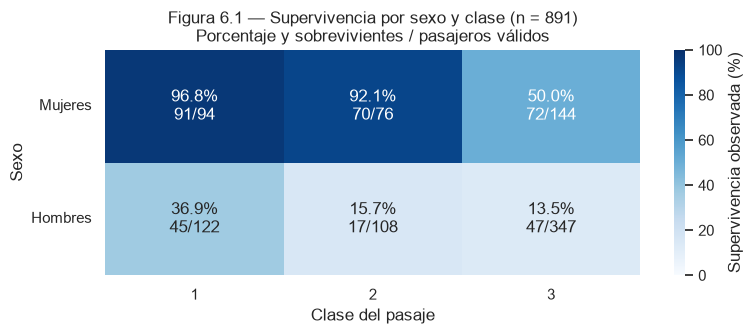

In [22]:
tasas = por_cruce["tasa_pct"].unstack("pclass").reindex(["female", "male"])
anotaciones = tasas.copy().astype(object)
for sexo in tasas.index:
    for clase in tasas.columns:
        fila = por_cruce.loc[(sexo, clase)]
        anotaciones.loc[sexo, clase] = f"{fila.tasa_pct:.1f}%\n{int(fila.sobrevivientes)}/{int(fila.pasajeros_validos)}"
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(tasas, annot=anotaciones, fmt="", vmin=0, vmax=100, cmap="Blues",
            cbar_kws={"label": "Supervivencia observada (%)"}, ax=ax)
ax.set(xlabel="Clase del pasaje", ylabel="Sexo", yticklabels=["Mujeres", "Hombres"],
       title="Figura 6.1 — Supervivencia por sexo y clase (n = 891)\nPorcentaje y sobrevivientes / pasajeros válidos")
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()


**Interpretación (Figura 6.1).** Las mujeres de primera y segunda clase presentan las tasas más altas; los hombres de tercera, la menor. Dentro de cada sexo, las tasas disminuyen de primera a tercera clase. Los conteos anotados permiten distinguir proporciones de cantidades y comprobar cada celda contra la Tabla 6.5.

**Limitaciones para el traspaso.** La edad incompleta y su composición por clase condicionan P2; la cubierta tiene cobertura desigual; las coincidencias sin identificador no permiten verificar unicidad; `who` no reemplaza la edad; y P3 sigue siendo descriptiva, sin control de confusores ni inferencia al total del pasaje. No se generaron modelos predictivos ni pruebas de hipótesis.

**Referencia técnica oficial (APA 7).** The pandas development team. (s. f.). *pandas.DataFrame.groupby*. pandas documentation. Recuperado el 24 de noviembre de 2026, de https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html


## VII. Supuestos y limitaciones

Esta sección consolida las condiciones bajo las que deben leerse los resultados de la sección VI. Cada supuesto y cada limitación se vincula con la pregunta, la decisión o la tabla cuya interpretación condiciona.

### VII.1 Supuestos considerados

| Id | Supuesto | Dónde se aplicó | Qué cambiaría si no se cumple |
|---|---|---|---|
| S1 | Cada fila corresponde a un pasajero distinto, aunque no hay identificador | D4: se conservan las 107 filas coincidentes (III.4.4) | Los conteos de P3 podrían estar inflados en hasta 107 registros (Tablas 6.3–6.5) |
| S2 | Los 891 registros son una muestra del pasaje, sin tripulación | Tasas de P3 (VI.3) | Las tasas describen esta muestra y no a todas las personas a bordo |
| S3 | Las diferencias entre grupos son asociaciones descriptivas | Interpretación de Tablas 6.3–6.5 y Figura 6.1 | Afirmar efectos causales exigiría controlar variables confusoras |
| S4 | Los valores registrados son correctos salvo evidencia de error | III.4.2 (0 fuera de dominio); D9 conserva tarifas 0 y > 500 | Ceros o extremos erróneos desplazarían la media de `fare` (Tabla 4.1) |

### VII.2 Limitaciones detectadas

**Qué y por qué.** La evidencia de cada limitación se recalcula desde `df_raw`, de modo que las cifras de la tabla no se escriben a mano y coinciden con las secciones III–VI.

In [23]:
def pct(valor):
    """Porcentaje con coma decimal, igual que en la narrativa del notebook."""
    return f"{valor:.1f}".replace(".", ",")


edad_falt_clase = df_raw.groupby("pclass")["age"].apply(lambda s: s.isna().mean() * 100)
limitaciones = pd.DataFrame(
    [
        ["L1", "Datos", "deck",
         f"{df_raw['deck'].isna().sum()} faltantes ({pct(df_raw['deck'].isna().mean() * 100)} %); "
         f"faltan sobre todo en 2.ª y 3.ª clase",
         "No se compara supervivencia por cubierta", "P1 · Tablas 3.4 y 4.2"],
        ["L2", "Datos", "age",
         f"{df_raw['age'].isna().sum()} faltantes ({pct(df_raw['age'].isna().mean() * 100)} %); "
         f"{pct(edad_falt_clase[3])} % en 3.ª clase frente a {pct(edad_falt_clase[2])} % en 2.ª",
         "La edad descrita (n = 714) subrepresenta a 3.ª clase", "P2 · Tablas 4.1, 4.2 y 6.2"],
        ["L3", "Datos", "who / adult_male",
         f"Los {df_raw['age'].isna().sum()} pasajeros sin edad figuran como adultos",
         "No sirven como sustituto de la edad", "P1 · Tabla 3.7b"],
        ["L4", "Datos", "fila completa",
         f"{df_raw.duplicated().sum()} filas coinciden con otra; sin ID no es verificable",
         "Conteos de P3 bajo el supuesto S1", "P1, P3 · Tablas 3.8a–3.8b"],
        ["L5", "Datos", "age / fare",
         f"{int(((df_raw['age'] >= 1) & (df_raw['age'] % 1 == 0.5)).sum())} edades estimadas; "
         f"{int(df_raw['fare'].eq(0).sum())} tarifas en cero; libras de 1912 sin ajuste",
         "Precisión limitada de edad y tarifa", "P2 · Tablas 3.6 y 6.2"],
        ["L6", "Alcance", "sex × pclass",
         "Análisis descriptivo, sin inferencia ni control de confusores",
         "Las diferencias de P3 son asociaciones de esta muestra", "P3 · Tabla 6.5, Figura 6.1"],
    ],
    columns=["id", "tipo", "variable", "evidencia", "efecto en la interpretación", "pregunta y evidencia"],
).set_index("id")
print("Tabla 7.1 — Limitaciones detectadas y análisis que condicionan")
display(limitaciones)

Tabla 7.1 — Limitaciones detectadas y análisis que condicionan


,tipo,variable,evidencia,efecto en la interpretación,pregunta y evidencia
id,,,,,
L1,Datos,deck,"688 faltantes (77,2 %); faltan sobre todo en 2...",No se compara supervivencia por cubierta,P1 · Tablas 3.4 y 4.2
L2,Datos,age,"177 faltantes (19,9 %); 27,7 % en 3.ª clase fr...",La edad descrita (n = 714) subrepresenta a 3.ª...,"P2 · Tablas 4.1, 4.2 y 6.2"
L3,Datos,who / adult_male,Los 177 pasajeros sin edad figuran como adultos,No sirven como sustituto de la edad,P1 · Tabla 3.7b
L4,Datos,fila completa,107 filas coinciden con otra; sin ID no es ver...,Conteos de P3 bajo el supuesto S1,"P1, P3 · Tablas 3.8a–3.8b"
L5,Datos,age / fare,18 edades estimadas; 15 tarifas en cero; libra...,Precisión limitada de edad y tarifa,P2 · Tablas 3.6 y 6.2
L6,Alcance,sex × pclass,"Análisis descriptivo, sin inferencia ni contro...",Las diferencias de P3 son asociaciones de esta...,"P3 · Tabla 6.5, Figura 6.1"


**Interpretación (Tabla 7.1).** Las limitaciones L1–L5 provienen de los datos y L6 del alcance definido para la fase. Ninguna impide responder P1–P3, pero todas acotan cómo leer las respuestas: P3 se apoya en variables completas (891 casos), mientras que P2 describe solo a los pasajeros con edad registrada, con menor presencia relativa de tercera clase.

### VII.3 Aspectos pendientes que condicionan fases posteriores

- **Tratamiento de `age`.** Evaluar una imputación (por ejemplo, por sexo y clase) y comparar los resultados con y sin ella antes de usar la edad en análisis de supervivencia.
- **Variables no exploradas.** `sibsp`, `parch`, `alone` y `embarked` no se analizaron en esta fase; su relación con la supervivencia queda abierta.
- **Edad y supervivencia.** Relacionar la edad con `survived` informando siempre el número de casos válidos (L2).
- **Tablas derivadas.** Construir tablas agregadas (por ejemplo, por grupo familiar o por clase) para los ejercicios de integración que plantea el curso.
- **Mayor profundidad analítica.** Si las fases siguientes lo requieren, incorporar pruebas estadísticas o modelos que controlen la relación entre sexo y clase (L6).

## VIII. Cierre del avance

### VIII.1 Síntesis del trabajo realizado

Se implementó un primer ciclo de EDA reproducible sobre `titanic`: carga desde una copia congelada verificada con SHA-256 (III.2), diagnóstico de calidad en cuatro dimensiones (III.4), exploración de edad, tarifa y composición de la muestra (IV), once decisiones documentadas con su efecto antes y después (V) y respuestas a P1–P3 (VI). El entorno está fijado en `uv.lock`, `df_raw` se mantiene intacto y el notebook se ejecuta completo desde un kernel limpio (VIII.3).

### VIII.2 Principales hallazgos de la fase

- **P1, calidad.** No hay valores fuera de dominio ni contradicciones entre columnas redundantes. Los problemas están en la completitud (`deck` 77,2 %, `age` 19,9 %) y en la unicidad, que no puede verificarse (Tablas 3.9 y 6.1).
- **P2, distribuciones.** Edad mediana de 28 años (n = 714). Tarifa mediana de 14,45 libras frente a una media de 32,20, con cola derecha larga (Tabla 6.2; Figuras 4.1 y 5.1).
- **P3, supervivencia.** 74,20 % en mujeres frente a 18,89 % en hombres, y 62,96 %, 47,28 % y 24,24 % de primera a tercera clase. La mayor supervivencia femenina se mantiene dentro de cada clase (Tablas 6.3–6.5; Figura 6.1).

### VIII.3 Comprobación final de reproducibilidad

**Qué y por qué.** La última celda verifica que los datos de entrada no cambiaron y que las cifras centrales citadas en el informe coinciden con las calculadas. Si alguna comprobación falla, el notebook se detiene con un error.

In [24]:
comprobaciones = pd.Series({
    "Huella SHA-256 de la copia congelada": sha256 == SHA256_ESPERADO,
    "df_raw sin cambios (891 × 15)": df_raw.equals(original_control) and df_raw.shape == FORMA_ESPERADA,
    "df de trabajo: 891 filas y 13 columnas": df.shape == (891, 13),
    "Edad válida n = 714": int(mask_edad.sum()) == 714,
    "P3: 891 pasajeros y 342 sobrevivientes": (int(df["survived"].count()), int(df["survived"].sum())) == (891, 342),
    "Tasas por sexo 74,20 % / 18,89 %": por_sexo["tasa_pct"].round(2).tolist() == [74.20, 18.89],
}, name="cumple")
assert comprobaciones.all(), "Alguna comprobación falló: revisar antes de entregar."
print("Tabla 8.1 — Comprobación final de reproducibilidad")
display(comprobaciones.to_frame())

Tabla 8.1 — Comprobación final de reproducibilidad


,cumple
Huella SHA-256 de la copia congelada,True
df_raw sin cambios (891 × 15),True
df de trabajo: 891 filas y 13 columnas,True
Edad válida n = 714,True
P3: 891 pasajeros y 342 sobrevivientes,True
"Tasas por sexo 74,20 % / 18,89 %",True


**Resultado (Tabla 8.1).** Todas las comprobaciones se cumplen: el flujo va de los mismos datos de entrada a los mismos resultados en cada ejecución.

### VIII.4 Continuidad para las siguientes fases

La Fase 1 deja una línea base verificable: datos de entrada fijados, decisiones D1–D11 trazables y limitaciones L1–L6 identificadas. En las fases siguientes se abordarán los pendientes de VII.3, partiendo del tratamiento de la edad y de las variables familiares y de embarque no exploradas aquí. Toda nueva transformación continuará el registro desde **D12**, se aplicará sobre `df` y conservará `df_raw` intacto.